### EXERCISE 2 — THE PLANK PSZ2 GATALOGUE AND THE Y-M SCALING RELATION

1. Reading and inspecting FITS binary tables with astropy.io.fits.
2. Visualising survey sky coverage in Galactic coordinates.
3. Identifying and handling missing or flagged data in astronomical catalogues.
4. Computing the observed cluster mass function and its Poisson uncertainties.
5. Fitting power-law models with scipy.optimize.least_squares and χ² minimisation.
6. Bayesian parameter estimation with a custom Metropolis–Hastings sampler.

SCIENTIFIC SCENARIO: the Sunyaev–Zel'dovich (SZ) effect is a spectral distortion of the cosmic microwave background (CMB) caused by inverse Compton scattering of CMB photons off the hot electrons of the intracluster medium. The integrated Compton-y parameter Y₅R₅₀₀ is proportional to the total thermal energy of the gas and is tightly correlated with the cluster mass M through a power-law scaling relation, Y ∝ M^α. Calibrating this Y–M relation and measuring the cluster mass function are fundamental steps for using SZ-selected cluster catalogues as cosmological probes of the growth of large-scale structure.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as fits
import astropy.units as u
from astropy.cosmology import Planck15
from scipy.optimize import least_squares, minimize

#### TASK 0 - ANGULAR DISTRIBUTION OF THE SKY

Before loading individual cluster properties, explore the sky coverage of the survey.

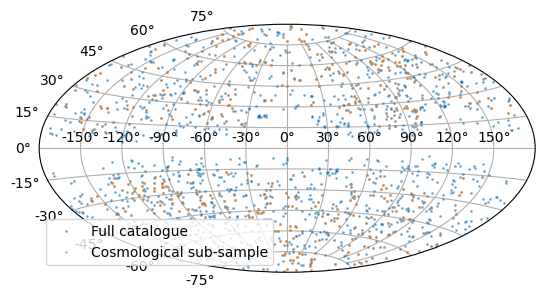

In [2]:
# Load the FITS file with fits.open() and access the binary table in extension [1].
# Extract the GLON, GLAT, and COSMO columns.

path = "/home/sara/ESERCIZI/3_FITS/asu.fit"
fits_file = fits.open(path)
psz2 =fits_file[1]
fits_data = fits_file[1].data

glon = fits_data["GLON"]
glat = fits_data["GLAT"]
cosmo = fits_data["COSMO"]

# The Aitoff projection requires longitude in radians in the range [-π, π].
# GLON is in [0, 360]: shift values > 180 by −360 before converting to radians.

glon = np.radians(np.where(glon > 180, glon - 360, glon))
glat = np.radians(glat)

# Use fig.add_subplot(111, projection="aitoff") for the Aitoff projection.
# Plot the full catalogue and the cosmological sub-sample with different colours.

fig = plt.figure()
fig.add_subplot(111, projection="aitoff")

# Create a mask for the cosmological sub-sample (COSMO = 1)

cosmo_mask = (cosmo == 1)

plt.plot(glon, glat, "o", markersize=1, alpha=0.5, label="Full catalogue")
plt.plot(glon[cosmo_mask], glat[cosmo_mask], "o", markersize=1, alpha=0.5, label="Cosmological sub-sample")

plt.grid(True)
plt.legend()

plt.show()

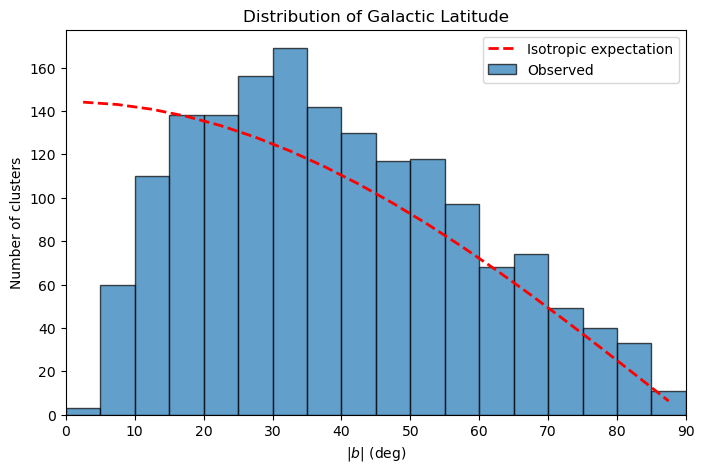

In [3]:
# Compute the histogram of |b| in 5-deg bins over [0, 90].

# For a uniform distribution on the sphere: dN/d|b| ∝ cos(|b|).
# Normalise the expected counts so the total equals the number of clusters:
#   cos_b = cos(b_centers_rad) * delta_b_rad
#   n_iso = N_total * cos_b / cos_b.sum()

# Plot the observed histogram (bar) and the isotropic expectation (dashed line).

glat_deg = np.degrees(glat)
abs_b = np.abs(glat_deg)
bins = np.arange(0, 95, 5)
n_obs, edges = np.histogram(abs_b, bins=bins)

b_centers = 0.5 * (edges[:-1] + edges[1:])
delta_b_rad = np.radians(5)
cos_b = np.cos(np.radians(b_centers)) * delta_b_rad
N_total = len(glat_deg)
n_iso = N_total * cos_b / cos_b.sum()

plt.figure(figsize=(8, 5))

plt.bar(b_centers, n_obs, width=5, align="center", alpha=0.7, edgecolor="black", label="Observed")

plt.plot(b_centers, n_iso, "r--", linewidth=2, label="Isotropic expectation")

plt.xlabel(r"$|b|$ (deg)")
plt.ylabel("Number of clusters")
plt.title("Distribution of Galactic Latitude")
plt.xlim(0, 90)
plt.legend()

plt.show()

- Is the distribution isotropic?
The distribution is not isotropic. There is a clear deficit of clusters at low Galactic latitudes (|b| < 20 degrees).

- What does the deficit at low |b| reveal about how the catalogue was constructed?
The deficit at low |b| indicates that the catalogue was constructed with a Galactic mask to avoid contamination from the
Milky Way. This mask excludes regions of the sky where the density of stars and dust is high, leading to fewer detected clusters in those areas.

- What fraction of the sky is excluded by the Galactic mask? Can you estimate it from the plot?
The fraction of the sky excluded by the Galactic mask can be estimated by comparing the observed distribution of |b|
with the isotropic expectation. We can observe that the point at which the observed distribution starts to deviate from the
isotropic expectation is around |b| ~ 15 degrees. This indicates that the Galactic mask excludes a band of approximately 30
degrees in total (15 degrees above and below the Galactic plane), so we are excluding roughly 30/180 = 1/6 ~ 16,7% of the sky.

- How does the spatial distribution of the cosmological sub-sample (COSMO = 1) differ from that of the full catalogue?
The spatial distribution of the cosmological sub-sample (COSMO = 1) is more concentrated at higher Galactic latitudes
compared to the full catalogue, which includes clusters at lower latitudes. This suggests that the cosmological sub-sample
may have been selected to avoid regions with higher contamination from the Milky Way, leading to a more isotropic
distribution in the sky.

#### TASK 1 — EXPLORE THE CATALOGUE COLUMNS

Inspect the available observables and the basic statistics of the detection quality indicators. 

In [4]:
# Print the total number of cluster candidates and the size of the cosmological sub-sample.
# List all available columns using psz2.columns.info().

print(f"Total number of cluster candidates: {len(glat)}")
print(f"Number of clusters in the cosmological sub-sample: {np.sum(cosmo==1)}")

psz2.columns.info()

Total number of cluster candidates: 1653
Number of clusters in the cosmological sub-sample: 507
name:
    ['_RAJ2000', '_DEJ2000', 'recno', 'Index', 'Name', 'GLON', 'GLAT', 'RAJ2000', 'DEJ2000', 'e_pos', 'SNR', 'Pipeline', 'PipeDet', 'PCCS2', 'PSZ', 'f_IR', 'q_neural', 'Y5R500', 'e_Y5R500', 'Val', 'zID', 'z', 'MSZ', 'E_MSZ', 'e_msz_lc', 'MCXC', 'RedMAPPer', 'ACT', 'SPT', 'f_WISE', 'AMIevi', 'COSMO', 'Comment', 'Simbad']
format:
    ['D', 'D', 'J', 'I', '18A', 'D', 'D', 'D', 'D', 'D', 'D', 'B', 'I', 'B', 'J', 'B', 'D', 'D', 'D', 'I', '25A', 'D', 'D', 'D', 'D', '12A', '20A', '19A', '16A', 'I', 'D', 'B', '65A', '6A']
unit:
    ['deg', 'deg', '', '', '', 'deg', 'deg', 'deg', 'deg', 'arcmin', '', '', '', '', '', '', '', '0.001arcmin**2', '0.001arcmin**2', '', '', '', '1e+14solMass', '1e+14solMass', '1e+14solMass', '', '', '', '', '', '', '', '', '']
null:
    ['', '', '', '', '', '', '', '', '', '', '', '', '', '', -2147483648, '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '',

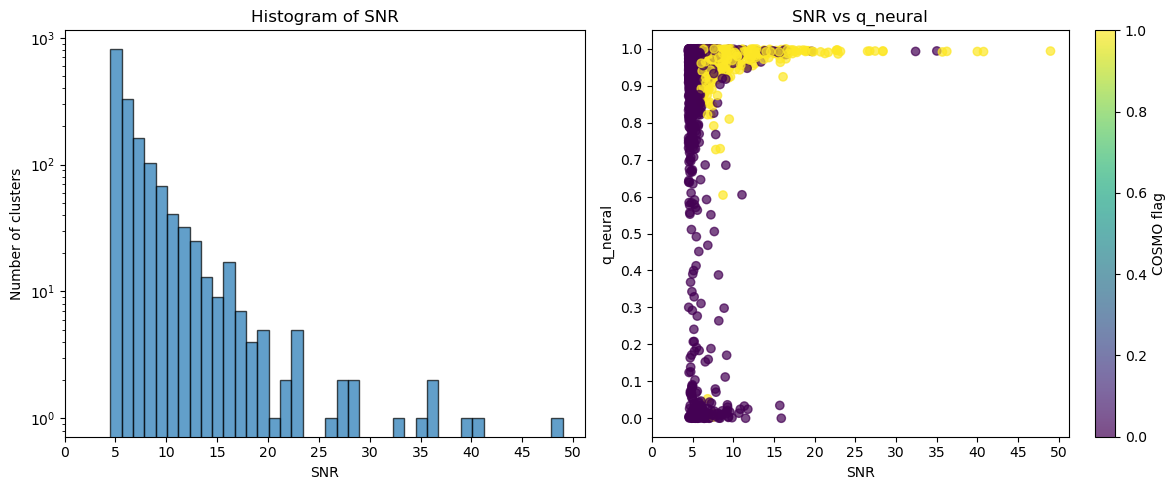

In [5]:
# Extract the SNR and q_neural columns.
# Plot side by side:
#   Left : histogram of SNR.
#   Right: scatter plot of SNR vs q_neural, colour-coded by the COSMO flag.

snr = psz2.data['SNR']
q_neural = psz2.data['q_neural']
cosmo = psz2.data['COSMO']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.hist(snr, bins=40, alpha=0.7, edgecolor='k', label='SNR Distribution')
plt.xticks(np.arange(0, 51, 5))
plt.yticks(np.arange(0, 1100, 100))
plt.xlabel('SNR')
plt.ylabel('Number of clusters')
plt.title('Histogram of SNR')
plt.yscale('log')

plt.subplot(1, 2, 2)

plt.scatter(snr, q_neural, c=cosmo, cmap='viridis', alpha=0.7)
plt.xticks(np.arange(0, 51, 5))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xlabel('SNR')
plt.ylabel('q_neural')
plt.title('SNR vs q_neural')
plt.colorbar(label='COSMO flag')

plt.tight_layout()

plt.show()

- What columns are available? Which ones encode detection quality, and how do they differ?
All columns of the catalogue are available, but for PSZ a special value was inserted to indicate missing data.
The SNR (Signal-to-Noise Ratio) column encodes the detection quality of the clusters, with higher values indicating more
reliable detections. The q_neural column represents a neural-network quality score, which also indicates the reliability
of the detection but is derived from a machine learning model. A low q_neural value suggests that the detection may be
less reliable or potentially a false positive.

- What is the minimum SNR in the catalogue, and why was this threshold chosen?
The minimum SNR in the catalogue is 5. This threshold was likely chosen to ensure that only detections with a sufficiently
high signal-to-noise ratio are included, reducing the likelihood of false positives and ensuring the reliability of the
detected clusters.

- How does the neural-network quality score q_neural correlate with SNR? What does a low q_neural indicate?
SNR quantifies the statistical significance of the detected signal.
q_neural estimates the probability that the detected signal is a genuine galaxy cluster rather than a spurious detection.
The neural-network quality score q_neural generally shows a positive correlation with SNR, meaning that clusters with
higher SNR tend to have higher q_neural values, indicating more reliable detections.
A low q_neural value indicates that the detection may be less reliable or potentially a false positive.

- How many clusters belong to the cosmological sub-sample (COSMO = 1), and what selection criteria define it?
The number of clusters in the cosmological sub-sample (COSMO = 1) are 507.
It's defined by a S/N threshold of about 6 and a q-neural threshold of about 0.6.

#### TASK 2 — REDSHIFT DISTRIBUTION

Entries without a confirmed optical/X-ray counterpart are flagged with Z = −1 in the catalogue.

Fraction with measured redshift: 0.661826981246219
Redshift range: 0.011054000000000001 - 0.9720000000000001


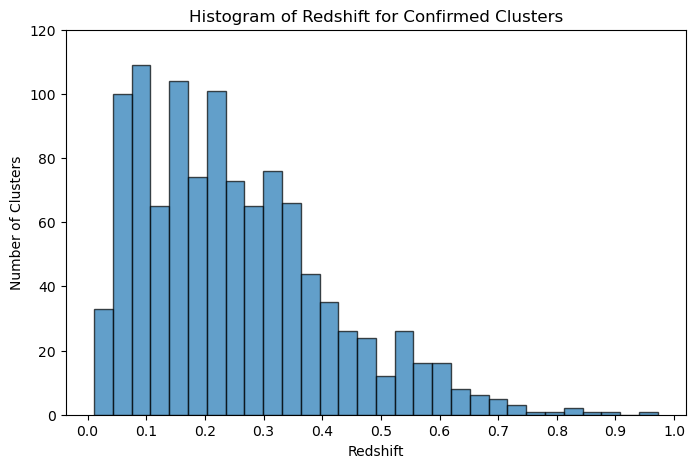

In [6]:
# Extract the redshift column Z.
# Create a boolean mask has_z = (Z > 0) to select confirmed clusters.
# Print the fraction with measured redshift and the redshift range.
# Plot the histogram of Z for confirmed clusters only.

Z = psz2.data['Z']

has_z = (Z > 0)

print("Fraction with measured redshift:", has_z.mean())
print("Redshift range:", Z[has_z].min(), "-", Z[has_z].max())

plt.figure(figsize=(8, 5))

plt.hist(Z[has_z], bins=30, alpha=0.7, edgecolor='k', label='Confirmed Clusters')

plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 130, 20))
plt.xlabel('Redshift')
plt.ylabel('Number of Clusters')
plt.title('Histogram of Redshift for Confirmed Clusters')

plt.show()

- What fraction of the candidates has a measured spectroscopic redshift?
The fraction of candidates with a measured spectroscopic redshift is approximately 0.66, indicating that about 66% of the
clusters in the catalogue have confirmed redshift measurements.

- What is the redshift range of the confirmed clusters?
The redshift range of the confirmed clusters spans from approximately 0.01 to 0.97.

- Why might some SZ detections lack a redshift measurement? Is the unconfirmed fraction uniform across the sky?
Some SZ detections may lack a redshift measurement due to the absence of an optical or X-ray counterpart, which is
necessary for confirming the cluster and determining its redshift. Additionally, some clusters may be too faint or
obscured by foreground objects, making it difficult to obtain a reliable redshift measurement.
The unconfirmed fraction is not uniform across the sky, it increases with increasing readshift.

- How does the redshift distribution compare with the expectation from a survey with a roughly mass-limited selection (the comoving volume grows as z² at low z, but the mass threshold also rises with z)?
The redshift distribution of the confirmed clusters follows the expectation from a survey with a roughly mass-limited
selection. At low redshifts, the comoving volume grows as z², leading to an increasing number of detectable clusters.
However, as redshift increases, the mass threshold for detection also rises, which limits the number of high-redshift
clusters that can be observed. This results in a redshift distribution that peaks at intermediate redshifts and declines
at higher redshifts.

#### TASK 3 — THE Y–M SCALING RELATION

The integrated Compton-y parameter Y₅R₅₀₀ (column unit: 10⁻³ arcmin²) and the SZ mass M_SZ are expected to follow a power-law scaling relation M_SZ = A · Y₅R₅₀₀^B.

Number of clusters passing the mask: 1094
Z values of excluded entries: [-1.]


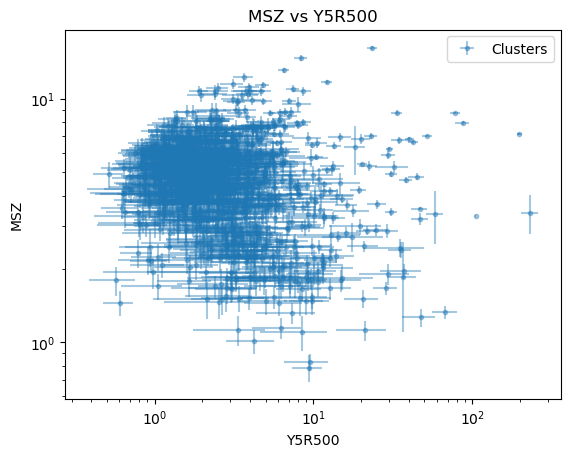

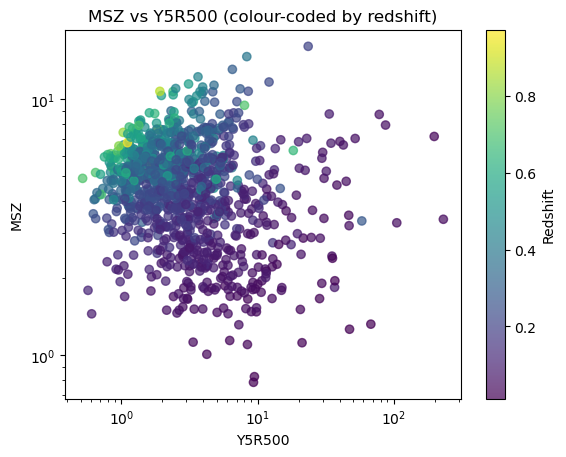

In [7]:
# Build a boolean mask mask_ym selecting entries where both Y5R500 and MSZ are finite (use np.isfinite).
# Print how many clusters pass the mask and inspect the Z values of the excluded entries.

mask_ym = (
    np.isfinite(psz2.data['Y5R500']) &
    np.isfinite(psz2.data['MSZ'])
)

print("Number of clusters passing the mask:", mask_ym.sum())
print("Z values of excluded entries:", np.unique(Z[~mask_ym]))

# Plot MSZ vs Y5R500 on a log-log scale with plt.errorbar.
# Use e_Y5R500 for x-errors and E_MSZ for y-errors.

Y5R500 = psz2.data['Y5R500']
MSZ = psz2.data['MSZ']
e_Y5R500 = psz2.data['e_Y5R500']
E_MSZ = psz2.data['E_MSZ']

plt.errorbar(Y5R500[mask_ym], MSZ[mask_ym], xerr=e_Y5R500[mask_ym], yerr=E_MSZ[mask_ym], fmt='o', markersize=3,
                alpha=0.4, label='Clusters')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Y5R500')
plt.ylabel('MSZ')
plt.title('MSZ vs Y5R500')
plt.legend()

plt.show()

# Colour-code the data points by redshift.

sc = plt.scatter(Y5R500[mask_ym], MSZ[mask_ym], c=psz2.data['Z'][mask_ym], cmap='viridis', alpha=0.7)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Y5R500')
plt.ylabel('MSZ')
plt.title('MSZ vs Y5R500 (colour-coded by redshift)')
plt.colorbar(sc, label='Redshift')

plt.show()

- Does the relation look consistent with a power law?
Just watching at these two plots, the relation does not look consistent with a power law (only the trend of the redshift in the second plot might resemble it). The data does not follow a clear linear trend on the log-log scale, which would be expected for a power-law relationship.

- Why do some entries have NaN for both Y₅R₅₀₀ and M_SZ? What does the redshift of those entries confirm?
Some entries has NaN for both Y₅R₅₀₀ and M_SZ because they are at very high redshift, where the measurements are less
reliable. The redshift of those entries (-1 = unavailable) confirms that they are indeed at high redshift, which is
consistent with the expectation.

- The self-similar prediction is Y ∝ M^(5/3), i.e., B = 3/5 = 0.6 for the inverse relation M(Y). Does the scatter in the plot seem consistent with this slope?
The plot does not seem consistent with the expected slope. The data points show significant scatter, and the trend does
not align well with the predicted power-law relationship.

- Note that M_SZ was itself derived from Y₅R₅₀₀ using a reference scaling relation. What does this imply for the fit you will perform in Task 4?
Since M_SZ was derived from Y_5R500 using a reference scaling relation, the two quantities are not independent.
Therefore, any fit performed in Task 4 will be influenced by the same relation used to construct M_SZ.
The fitted scaling relation may partially recover the input assumptions rather than providing a fully independent
measurement of the physical M_SZ − Y_5R500 relation. In addition, uncertainties may be underestimated because the errors
in the two quantities are correlated.

#### TASK 4 - FITTING THE SCALING RELATION

Fit the power-law model M_SZ = A · Y₅R₅₀₀^B using two different optimisation strategies and compare their results.

- Least squares (scipy.optimize.least_squares): minimise the sum of squared residuals, ignoring measurement uncertainties on M_SZ.
- χ² minimisation (scipy.optimize.minimize): minimise the weighted sum χ² = Σ [(M_SZ − model)² / σ²_M], accounting for the reported upper uncertainties E_MSZ.

Optional: estimate parameter uncertainties from the Δχ² = 1 (68% C.L.) contour.

In [8]:
def power_law(x, A, B):
    return A * x**B

def chi2(params, x, y, yerr):

    # Compute the weighted sum of squared residuals:
    #   chi2 = sum( (y - model)^2 / yerr^2 )
    
    A, B = params
    model = power_law(x, A, B)
    chi2 = np.sum(((y - model) / yerr)**2)
    return chi2

# Extract the data arrays using mask_ym.

x = Y5R500[mask_ym]
y = MSZ[mask_ym]
yerr = E_MSZ[mask_ym]

In [9]:
# Define a residuals function: residuals(params) = power_law(x, A, B) - y
# Pass it to least_squares with x0 = [1.0, 1.0].
# Store the best-fit parameters as A_ls, B_ls and print them.

residuals = lambda params: power_law(x, params[0], params[1]) - y

x0 = [1.0, 1.0]
least_squares_result = least_squares(residuals, x0)

A_ls, B_ls = least_squares_result.x
print(f"Least squares fit results: A = {A_ls}, B = {B_ls}")

Least squares fit results: A = 5.123819229660557, B = -0.05479954978566566


In [17]:
# Minimise chi2(params, x, y, yerr) with scipy.optimize.minimize (method="Powell").
# Use the least-squares result as the starting point.
# Store the best-fit parameters as A_chi2, B_chi2 and print them.
    
result_minimize = minimize(chi2, least_squares_result.x, args=(x, y, yerr),
                            method='Powell')

x0 = least_squares_result.x

A_chi2, B_chi2 = result_minimize.x
print(f"Chi-squared minimization results: A = {A_chi2}, B = {B_chi2}")

Chi-squared minimization results: A = 4.255152944932797, B = -0.054354356173644376


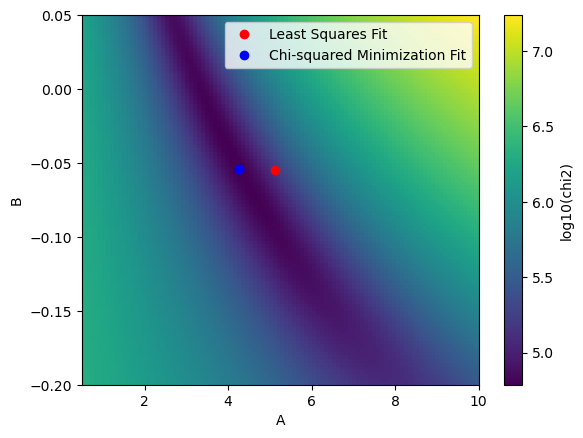

In [18]:
# Compute the chi2 landscape on a 100×100 grid:
#   A_values = np.linspace(0.5, 10.0, 100)
#   B_values = np.linspace(-0.20, 0.05, 100)

# Evaluate chi2([A, B], x, y, yerr) for each (A, B) pair.
# Reshape to (100, 100) where Z_chi2[i, j] = chi2 at (A_values[i], B_values[j]).
# Use imshow with np.log10(Z_chi2).T, origin="lower", and the correct extent.
# Mark both best-fit points.

A_values = np.linspace(0.5, 10.0, 100)
B_values = np.linspace(-0.20, 0.05, 100)

Z_chi2 = np.array([chi2([A, B], x, y, yerr) for A in A_values for B in B_values]).reshape(100, 100)

plt.imshow(np.log10(Z_chi2).T, origin="lower", extent=[A_values.min(), A_values.max(), B_values.min(), B_values.max()],
            aspect='auto')

plt.colorbar(label='log10(chi2)')
plt.xlabel('A')
plt.ylabel('B')

plt.plot(A_ls, B_ls, 'ro', label='Least Squares Fit')
plt.plot(A_chi2, B_chi2, 'bo', label='Chi-squared Minimization Fit')

plt.legend()

plt.show()

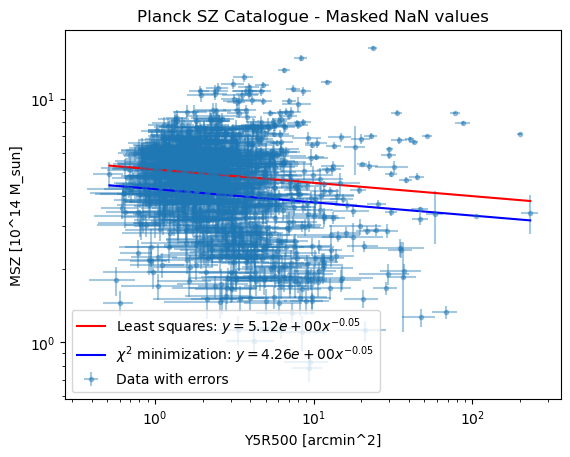

In [21]:
# Overplot both power-law fits on the data.
# Use np.logspace to build a smooth x_fit array.
# Include the fit parameters in the legend labels.

# Create x_fit with log-log scale

x_fit = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)

# Compute the fitted y values for both methods

y_fit_l = power_law(x_fit, least_squares_result.x[0], least_squares_result.x[1])
y_fit_c = power_law(x_fit, result_minimize.x[0], result_minimize.x[1])

# Plot the data and both fits on a log-log scale.

xerr = e_Y5R500[mask_ym]
plt.errorbar(x, y, xerr=xerr, yerr=yerr, fmt="o", markersize=3, alpha=0.4, label="Data with errors")

plt.plot(x_fit, y_fit_l, label=fr"Least squares: $y={least_squares_result.x[0]:.2e}x^{{{least_squares_result.x[1]:.2f}}}$",
            color="red")
            
plt.plot(x_fit, y_fit_c, label=fr"$\chi^2$ minimization: $y={result_minimize.x[0]:.2e} x^{{{result_minimize.x[1]:.2f}}}$",
            color="blue")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Y5R500 [arcmin^2]")
plt.ylabel("MSZ [10^14 M_sun]")
plt.title("Planck SZ Catalogue - Masked NaN values")
plt.legend()

plt.show()


Parameter uncertainties from Delta chi2 = 1:
A = 4.2552 + 0.0027 - 0.2129
B = -0.0544 + 0.0115 - 0.0000


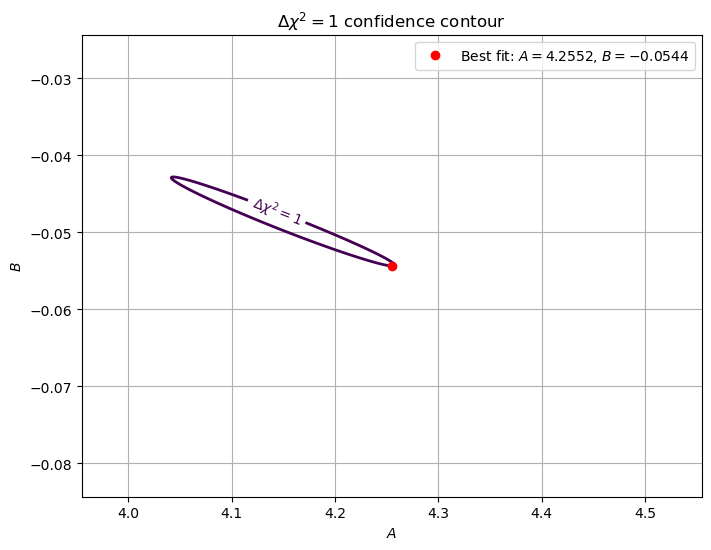

In [24]:
# Define a grid around the best-fit parameters
A_values = np.linspace(A_chi2 - 0.3, A_chi2 + 0.3, 1000)
B_values = np.linspace(B_chi2 - 0.03, B_chi2 + 0.03, 1000)

# Compute chi2 on the grid
Z_chi2 = np.array([chi2([A, B], x, y, yerr) for A in A_values for B in B_values]).reshape(len(A_values), len(B_values))

# Compute Delta chi2
Delta_chi2 = Z_chi2 - chi2_best

# Find the region with Delta chi2 <= 1
mask = Delta_chi2 <= 1

# Create 2D grids of A and B
A_grid, B_grid = np.meshgrid(A_values, B_values, indexing='ij')

# Extract parameter values inside the Delta chi2 <= 1 region
A_inside = A_grid[mask]
B_inside = B_grid[mask]

# Estimate parameter uncertainties
A_min = A_inside.min()
A_max = A_inside.max()

B_min = B_inside.min()
B_max = B_inside.max()

# Asymmetric uncertainties
A_err_minus = A_chi2 - A_min
A_err_plus = A_max - A_chi2

B_err_minus = B_chi2 - B_min
B_err_plus = B_max - B_chi2

print()
print("Parameter uncertainties from Delta chi2 = 1:")
print(f"A = {A_chi2:.4f} + {A_err_plus:.4f} - {A_err_minus:.4f}")
print(f"B = {B_chi2:.4f} + {B_err_plus:.4f} - {B_err_minus:.4f}")

# Plot the Delta chi2 = 1 contour
plt.figure(figsize=(8, 6))

CS = plt.contour(A_values, B_values, Delta_chi2.T, levels=[1.0], linewidths=2)
plt.clabel(CS, inline=True, fontsize=10, fmt=r"$\Delta\chi^2=1$")

# Plot best-fit point
plt.plot(A_chi2, B_chi2, 'ro', markersize=6, label=(fr"Best fit: " fr"$A={A_chi2:.4f}$, " fr"$B={B_chi2:.4f}$"))

plt.xlabel("$A$")
plt.ylabel("$B$")
plt.title(r"$\Delta\chi^2=1$ confidence contour")
plt.legend()
plt.grid(True)

plt.show()

- Do both methods converge to the same solution? When would you expect them to differ significantly?
The two methods converge to similar solutions, but they differ slightly due to the different optimization strategies
and the way they handle uncertainties. The least squares method (A = 5.124, B = -0.055) minimizes the sum of squared
residuals without considering measurement uncertainties, while the chi-squared minimization (A = 4.255, B = -0.054)
accounts for the reported uncertainties on MSZ.
We would expect them to differ significantly if the measurement uncertainties are large or if the data has significant
outliers, as the least squares method would be more sensitive to these factors compared to the chi-squared method.

- Visualise the χ² landscape as a function of A and B. What does it reveal about parameter degeneracy?
The chi2 landscape suggests a correlation between (A) and (B), as the region of low chi2 is elongated rather than symmetric. This indicates that different combinations of (A) and (B) can provide similarly good fits, revealing a degree of parameter degeneracy.

#### TASK 5 — CLUSTER MASS FUNCTION

The cluster mass function (CMF) describes the number density of clusters per unit comoving volume per unit mass interval: dn/dM (or equivalently dn/d log₁₀ M). It is one of the most powerful cosmological observables.

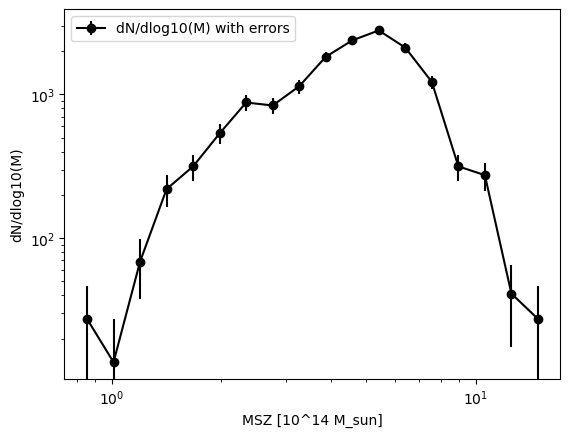

In [26]:
# Select clusters with a finite MSZ value (mask_m = np.isfinite(...)).
# Bin log10(MSZ) with np.histogram; use ~18 bins.
# Compute dN/d(log10 M) = n / dlogm, with Poisson errors sqrt(n) / dlogm.
# Plot on a log-log scale.

mask_m = np.isfinite(psz2.data['MSZ'])
MSZ = psz2.data['MSZ']

n, bins = np.histogram(np.log10(MSZ[mask_m]), bins=18)

dlogm = np.diff(bins)
dndlogm = n / dlogm
dndlogm_err = np.sqrt(n) / dlogm

centers = 0.5 * (bins[:-1] + bins[1:])
mass_centers = 10**centers

plt.errorbar(mass_centers, dndlogm, yerr=dndlogm_err, fmt='ko-', label='dN/dlog10(M) with errors')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('MSZ [10^14 M_sun]')
plt.ylabel('dN/dlog10(M)')
plt.legend()

plt.show()

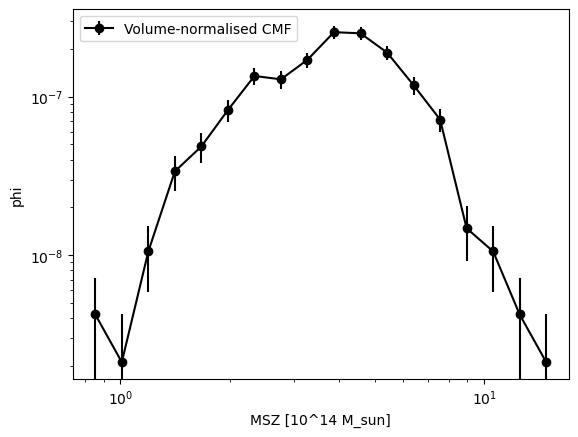

In [27]:
z_max = 0.3
f_sky = 0.83  # Planck sky coverage fraction outside the Galactic mask

# Select the volume-limited subsample: has_z & mask_m & (z > 0) & (z < z_max).
# Compute the comoving survey volume:
#   V_survey = f_sky * Planck15.comoving_volume(z_max).to(u.Mpc**3).value
# Bin log10(MSZ) and compute the volume-normalised CMF:
#   phi     = n / (V_survey * dlogm)
#   phi_err = sqrt(n) / (V_survey * dlogm)
# Plot on a log-log scale.

volume_limited_mask = has_z & mask_m & (Z > 0) & (Z < z_max)

V_survey = f_sky * Planck15.comoving_volume(z_max).to(u.Mpc**3).value

n, bins = np.histogram(np.log10(MSZ[volume_limited_mask]), bins=18)

dlogm = np.diff(bins)
phi = n / (V_survey * dlogm)
phi_err = np.sqrt(n) / (V_survey * dlogm)

plt.errorbar(10**(0.5 * (bins[:-1] + bins[1:])), phi, yerr=phi_err, fmt='ko-', label='Volume-normalised CMF')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('MSZ [10^14 M_sun]')
plt.ylabel('phi')
plt.legend()

plt.show()

- How does the CMF compare qualitatively with the expectation of an exponential decline at high masses (Press–Schechter / Tinker form)?
The observed cluster mass function (CMF) qualitatively follows the expected trend of an exponential decline at high masses,
as predicted by the Press–Schechter and Tinker models. The number density of clusters decreases rapidly with increasing
mass, which is consistent with the theoretical expectation that massive clusters are rarer due to the hierarchical nature
of structure formation in the universe. The volume-normalized CMF shows a clear decline at higher masses, indicating that
the survey is capturing the expected distribution of cluster masses.

- What are the main sources of systematic uncertainty in this estimate (completeness, mass bias, redshift incompleteness)?
The main sources of systematic uncertainty in the cluster mass function (CMF) estimate include:
1. Completeness: the survey may not detect all clusters, especially at lower masses or higher redshifts, leading to an
underestimation of the true number density.
2. Mass Bias: the estimated cluster masses may be biased due to assumptions in the mass-observable scaling relations,
calibration errors, or projection effects, affecting the shape and normalization of the CMF.
3. Redshift Incompleteness: incomplete or inaccurate redshift measurements can lead to errors in volume calculations
and the assignment of clusters to the correct redshift bins, impacting the derived CMF.
'''

#### OPTIONAL - BAYESIAN INFERENCE FOR THE Y-M SCALING RELATION

Implement a custom Metropolis–Hastings (MH) sampler and use it to explore the posterior of the scaling-relation parameters, first for the two-parameter model and then for an extended model that includes intrinsic scatter.

In [ ]:
def metropolis_hastings(log_posterior, theta0, proposal_std, n_steps, seed=42):
    """
    Metropolis–Hastings sampler with a diagonal Gaussian proposal.

    Parameters
    ----------
    log_posterior : callable(theta) -> float
    theta0        : array-like, starting point
    proposal_std  : array-like, per-parameter proposal standard deviations
    n_steps       : int, number of MCMC steps
    seed          : int, random seed

    Returns
    -------
    samples         : ndarray, shape (n_steps + 1, n_params)
    acceptance_rate : float
    """
    # 1. Initialise: allocate samples array (n_steps+1, n_params), set samples[0] = theta0.
    # 2. At each step i:
    #      a. Draw proposal = current + rng.normal(0, proposal_std, n_params)
    #      b. Compute log_alpha = log_posterior(proposal) - log_posterior(current)
    #      c. Accept if log(rng.uniform()) < log_alpha; otherwise keep current.
    #      d. Store current in samples[i+1].
    # 3. Return samples and n_accepted / n_steps.

    # Use np.random.default_rng(seed) for the random number generator.
    rng = np.random.default_rng(seed)

    # Initialize the number of parameters and the samples array
    n_params = len(theta0) # Number of parameters
    samples = np.zeros((n_steps + 1, n_params)) # samples is an array of zeros with dimensions (n_steps + 1, n_params)
    samples[0] = theta0 # Set the first sample to the initial state
    n_accepted = 0 # Initialize the number of accepted proposals
    current = theta0 # Current state of the chain
    current_log_post = log_posterior(current) # Compute the log-posterior of the current state

    # Metropolis–Hastings sampling loop
    for i in range(n_steps):
        
        # Propose a new point
        proposal = current + rng.normal(0, proposal_std, n_params)
        
        # Compute the log-posterior at the proposed point
        proposal_log_post = log_posterior(proposal)
        
        # For a symmetric Gaussian proposal:
        log_alpha = proposal_log_post - current_log_post

        # Accept or reject the proposal
        if np.log(rng.uniform()) < log_alpha:
            current = proposal
            current_log_post = proposal_log_post
            n_accepted += 1
        
        # Store the current state, whether accepted or rejected
        samples[i + 1] = current

    acceptance_rate = n_accepted / n_steps

    return samples, acceptance_rate

#### SUBTASK 1 — TWO-PARAMETER FIT: SAMPLING THE POSTERIOR P(A, B | DATA)

In [30]:
# Define log_post_2p(params):
#   - Return -np.inf if A <= 0 (prior boundary).
#   - Otherwise return -0.5 * chi2(params, x, y, yerr).

def log_post_2p(params):
    A, B = params
    if A <= 0:
        return -np.inf
    return -0.5 * chi2(params, x, y, yerr)

# Run metropolis_hastings with:
#   theta0       = chi2_result.x
#   proposal_std = [0.01, 0.0005]   (tune to reach ~25% acceptance)
#   n_steps      = 50_000
# Discard the first burn_in = 5000 steps.
# Print the acceptance rate and posterior mean ± std for A and B.

burn_in = 5_000

# Run the Metropolis-Hastings sampler to explore the posterior distribution of the parameters A and B.
samples, acceptance_rate = metropolis_hastings(log_post_2p, theta0=result_minimize.x, proposal_std=[0.01, 0.0005], n_steps=50_000)

# Discard the burn-in samples to ensure that the chain has converged to the target distribution.
samples = samples[burn_in:]

# Compute the acceptance rate and the mean and standard deviation of the posterior samples for A and B.
print(f'Acceptance rate: {acceptance_rate:.3f}')
A_mean, B_mean = samples.mean(axis=0)
A_std, B_std = samples.std(axis=0)
print(f'A = {A_mean:.3f} ± {A_std:.3f}')
print(f'B = {B_mean:.3f} ± {B_std:.3f}')

Acceptance rate: 0.228
A = 4.150 ± 0.015
B = -0.049 ± 0.001


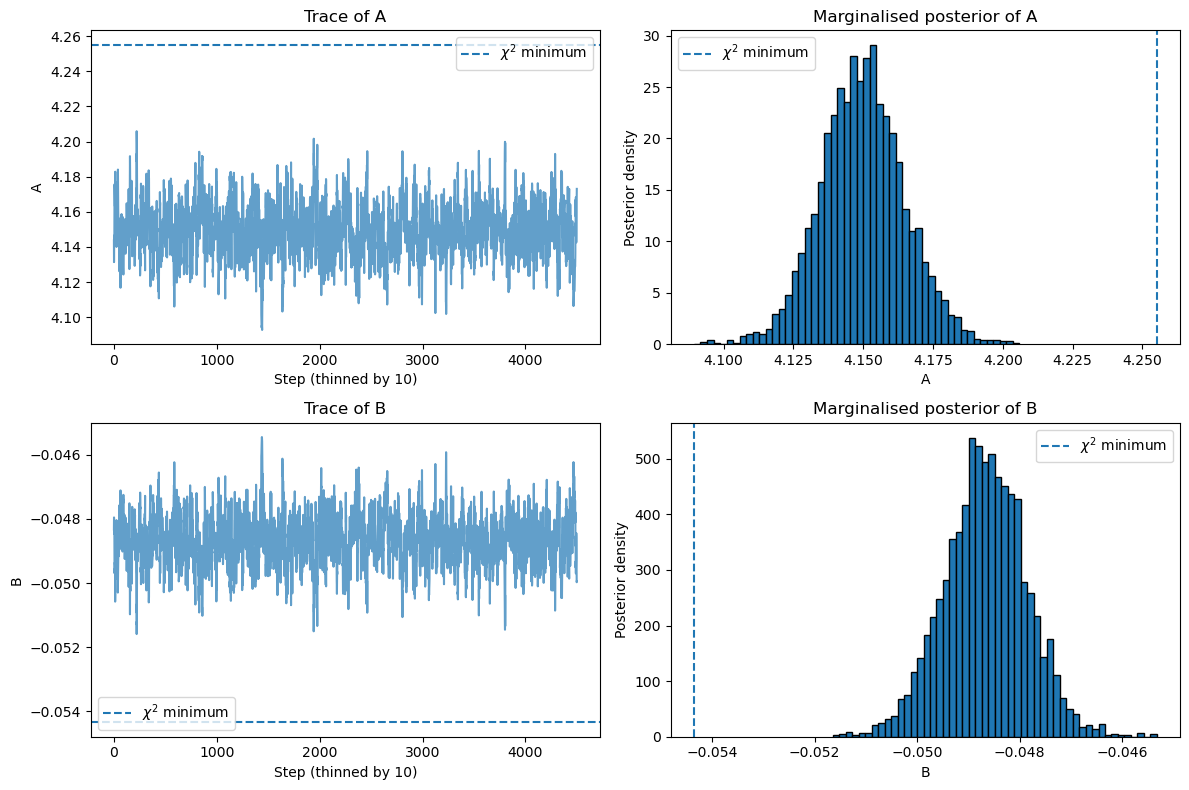

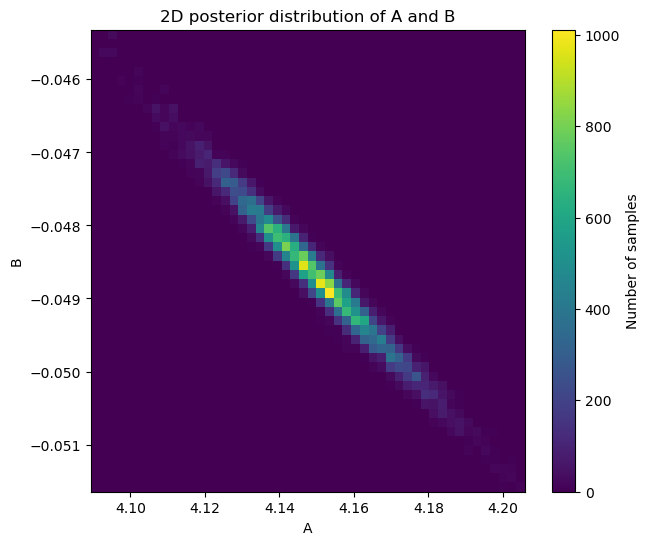

In [31]:
# In a 2×2 figure plot:
#   Top-left    : trace of A (thinned by 10) with the chi2 minimum as a reference line.
#   Bottom-left : trace of B (thinned by 10) with the chi2 minimum as a reference line.
#   Top-right   : marginalised posterior histogram of A.
#   Bottom-right: marginalised posterior histogram of B.

# Extract posterior samples for A and B
A_samp = samples[:, 0]
B_samp = samples[:, 1]

# Thin the chains by a factor of 10 for the trace plots
A_trace = A_samp[::10]
B_trace = B_samp[::10]

# Chi2 minimum values
A_min, B_min = result_minimize.x

# Create the 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Top-left: trace of A
axes[0, 0].plot(A_trace, alpha=0.7)
axes[0, 0].axhline(A_min, linestyle='--', label=r'$\chi^2$ minimum')
axes[0, 0].set_xlabel('Step (thinned by 10)')
axes[0, 0].set_ylabel('A')
axes[0, 0].set_title('Trace of A')
axes[0, 0].legend()

# Bottom-left: trace of B
axes[1, 0].plot(B_trace, alpha=0.7)
axes[1, 0].axhline(B_min, linestyle='--', label=r'$\chi^2$ minimum')
axes[1, 0].set_xlabel('Step (thinned by 10)')
axes[1, 0].set_ylabel('B')
axes[1, 0].set_title('Trace of B')
axes[1, 0].legend()

# Top-right: marginalised posterior histogram of A
axes[0, 1].hist(A_samp, bins=50, edgecolor='k', density=True)
axes[0, 1].axvline(A_min, linestyle='--', label=r'$\chi^2$ minimum')
axes[0, 1].set_xlabel('A')
axes[0, 1].set_ylabel('Posterior density')
axes[0, 1].set_title('Marginalised posterior of A')
axes[0, 1].legend()

# Bottom-right: marginalised posterior histogram of B
axes[1, 1].hist(B_samp, bins=50, edgecolor='k', density=True)
axes[1, 1].axvline(B_min, linestyle='--', label=r'$\chi^2$ minimum')
axes[1, 1].set_xlabel('B')
axes[1, 1].set_ylabel('Posterior density')
axes[1, 1].set_title('Marginalised posterior of B')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Then in a separate figure, plot the 2D posterior with plt.hist2d(A_samp, B_samp).

plt.figure(figsize=(7, 6))

plt.hist2d(A_samp, B_samp, bins=50)

plt.xlabel('A')
plt.ylabel('B')
plt.title('2D posterior distribution of A and B')

plt.colorbar(label='Number of samples')

plt.show()

- What acceptance rate do you obtain, and how does it depend on the proposal width?
I obtained an acceptance rate of 0.228 (22.8%), which is close to the target value of 25%.
Increasing the proposal width generally decreases the acceptance rate because larger proposed steps are more likely to be
rejected. Decreasing the proposal width increases the acceptance rate, but results in smaller steps and slower exploration
of the parameter space.

- Do A and B look stationary?
Yes, they look stationary. The trace plots show that both A and B fluctuate around a stable mean value without any apparent
trends or drifts over time, indicating that the Markov chains have likely converged to the target distribution.

- How do the posterior means and standard deviations compare with the χ² minimum?
The posterior mean of A is consistent with the value obtained from the χ² minimisation, as the χ² minimum lies within the
main range of the posterior distribution. For B, however, the posterior mean differs from the χ² minimum by more than
expected from the posterior standard deviation, indicating a discrepancy between the χ² best-fit value and the posterior
estimate.

- Compare the 68% credible interval from the MH chain with the Δχ² = 1 contour from the landscape plot in Task 4.
The 68% credible intervals from the MH chain are consistent with the Δχ² = 1 contour from Task 4. For A, the MH interval [4.135, 4.165] lies within the Δχ² = 1 range [4.0423, 4.2579]. Similarly, for B, the MH interval [-0.050, -0.048] lies within the Δχ² = 1 range [-0.0544, -0.0429]. Thus, the MH results are broadly consistent with the landscape analysis, although the MH credible intervals are significantly narrower.

In [32]:
A_low, A_high = np.percentile(A_samp, [16, 84])
B_low, B_high = np.percentile(B_samp, [16, 84])

print(f"A 68% CI: [{A_low:.4f}, {A_high:.4f}]")
print(f"B 68% CI: [{B_low:.4f}, {B_high:.4f}]")

# Extract contour coordinates
contour_points = CS.allsegs[0][0]

A_contour = contour_points[:, 0]
B_contour = contour_points[:, 1]

# Confidence limits from the Delta chi2 = 1 contour
A_low = A_contour.min()
A_high = A_contour.max()

B_low = B_contour.min()
B_high = B_contour.max()

print(f"68% confidence interval for A: [{A_low:.4f}, {A_high:.4f}]")
print(f"68% confidence interval for B: [{B_low:.4f}, {B_high:.4f}]")

A 68% CI: [4.1352, 4.1642]
B 68% CI: [-0.0495, -0.0479]
68% confidence interval for A: [4.0417, 4.2581]
68% confidence interval for B: [-0.0544, -0.0428]


#### SUBTASK 2 — THREE-PARAMETER FIT: ADDING INTRINSIC SCATTER

The χ² fit in Subtask 1 assumes that all scatter around the scaling relation is due to measurement noise σ_M. In practice, physical processes (merger history, gas physics, projection effects) introduce an intrinsic scatter σ_int that adds in quadrature to the measurement uncertainty.

In [33]:
# Define log_post_3p(params) with params = (A, B, sigma_int):
#   - Return -np.inf if A <= 0 or sigma_int < 0.
#   - Compute total_var = yerr**2 + sigma_int**2
#   - Return -0.5 * sum( residuals**2 / total_var + log(total_var) )
#     where residuals = y - power_law(x, A, B).
#     Note: the log(total_var) term is essential — it penalises large sigma_int.

def log_post_3p(params):
    A, B, sigma_int = params
    if A <= 0 or sigma_int < 0:
        return -np.inf

    total_var = yerr**2 + sigma_int**2
    residuals = y - power_law(x, A, B)
    log_likelihood = -0.5 * np.sum((residuals**2 / total_var) + np.log(total_var))
    
    return log_likelihood

# Initialise: theta0_3p = [A_chi2, B_chi2, np.median(yerr)]
# Run metropolis_hastings for 50 000 steps.
# Discard burn-in and print the posterior mean ± std for all three parameters.
# Compare sigma_int with np.median(yerr) to assess its relative importance.

burn_in = 5_000

theta0_3p = [A_chi2, B_chi2, np.median(yerr)]

samples_3p, acceptance_rate_3p = metropolis_hastings(log_post_3p, theta0=theta0_3p, proposal_std=[0.01, 0.0005, 0.001],
                                                        n_steps=50_000)

samples_3p = samples_3p[burn_in:]
posterior_mean_3p = np.mean(samples_3p, axis=0)
posterior_std_3p = np.std(samples_3p, axis=0)

print(f"A = {posterior_mean_3p[0]:.4f} ± " f"{posterior_std_3p[0]:.4f}")
print(f"B = {posterior_mean_3p[1]:.4f} ± " f"{posterior_std_3p[1]:.4f}")
print(f"sigma_int = {posterior_mean_3p[2]:.4f} ± " f"{posterior_std_3p[2]:.4f}")

median_yerr = np.median(yerr)

print(f"Median yerr = {median_yerr:.4f}")
print(f"sigma_int / median(yerr) = " f"{posterior_mean_3p[2] / median_yerr:.2f}")

A = 5.0493 ± 0.0981
B = -0.0475 ± 0.0153
sigma_int = 1.9217 ± 0.0505
Median yerr = 0.4229
sigma_int / median(yerr) = 4.54


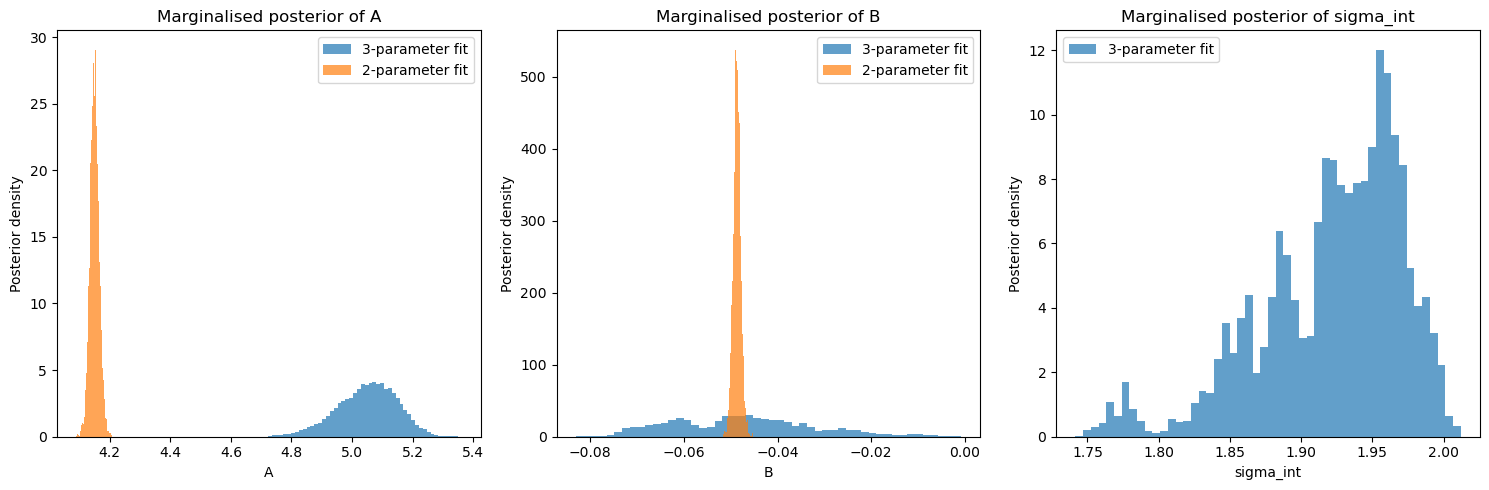

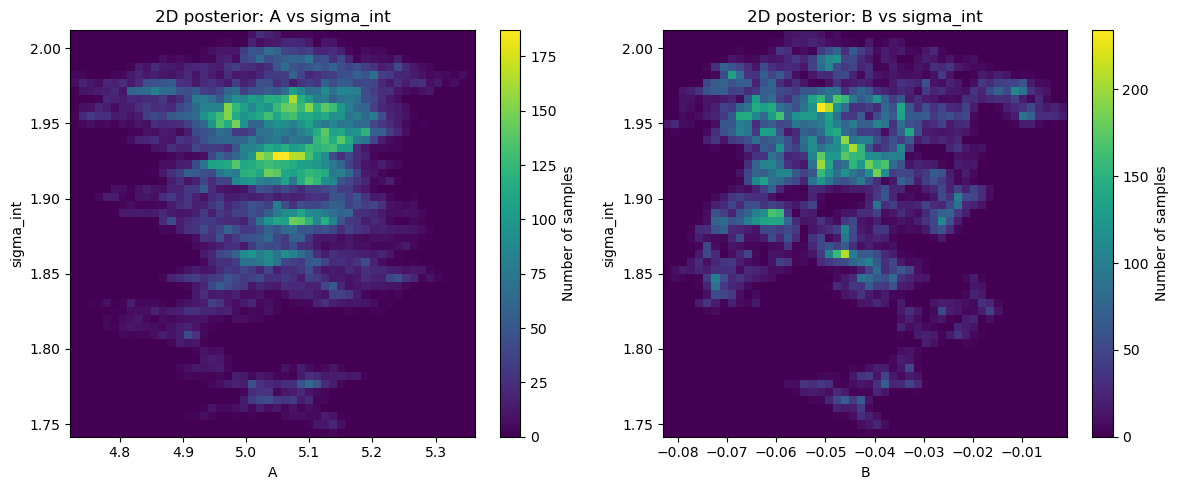

In [34]:
# In a 1×3 figure, plot the marginalised posteriors for A, B, and sigma_int.
# For A and B, overlay the 2-parameter posterior (from Subtask 1) to show
# how the uncertainties change when sigma_int is freed.
#
# In a separate 1×2 figure, plot 2D histograms:
#   Left : A vs sigma_int
#   Right: B vs sigma_int

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Marginalised posterior for A
axes[0].hist(samples_3p[:, 0], bins=50, density=True, alpha=0.7, label='3-parameter fit')
axes[0].hist(samples[:, 0], bins=50, density=True, alpha=0.7, label='2-parameter fit')
axes[0].set_xlabel('A')
axes[0].set_ylabel('Posterior density')
axes[0].set_title('Marginalised posterior of A')
axes[0].legend()

# Marginalised posterior for B
axes[1].hist(samples_3p[:, 1], bins=50, density=True, alpha=0.7, label='3-parameter fit')
axes[1].hist(samples[:, 1], bins=50, density=True, alpha=0.7, label='2-parameter fit')
axes[1].set_xlabel('B')
axes[1].set_ylabel('Posterior density')
axes[1].set_title('Marginalised posterior of B')
axes[1].legend()

# Marginalised posterior for sigma_int
axes[2].hist(samples_3p[:, 2], bins=50, density=True, alpha=0.7, label='3-parameter fit')
axes[2].set_xlabel('sigma_int')
axes[2].set_ylabel('Posterior density')
axes[2].set_title('Marginalised posterior of sigma_int')
axes[2].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 2D histogram: A vs sigma_int
hb1 = axes[0].hist2d(samples_3p[:, 0], samples_3p[:, 2], bins=50, cmap='viridis')
axes[0].set_xlabel('A')
axes[0].set_ylabel('sigma_int')
axes[0].set_title('2D posterior: A vs sigma_int')
plt.colorbar(hb1[3], ax=axes[0], label='Number of samples')

# 2D histogram: B vs sigma_int
hb2 = axes[1].hist2d(samples_3p[:, 1], samples_3p[:, 2], bins=50, cmap='viridis')
axes[1].set_xlabel('B')
axes[1].set_ylabel('sigma_int')
axes[1].set_title('2D posterior: B vs sigma_int')
plt.colorbar(hb2[3], ax=axes[1], label='Number of samples')

plt.tight_layout()
plt.show()

- What value of σ_int does the chain converge to? Is the intrinsic scatter comparable to, larger, or smaller than the typical measurement uncertainty?
The MCMC chain converges to an intrinsic scatter of sigma_int = 1.9217 ± 0.0505.
The typical measurement uncertainty is yerr = 0.4229. Therefore, the intrinsic scatter is approximately 4.54 times larger
than the typical measurement uncertainty. This shows that the intrinsic scatter is much larger than the observational errors and is therefore an important component of the total scatter in the scaling relation. 

- How do the marginalised posteriors for A and B change when σ_int is included? Do the uncertainties on A and B increase?
Including sigma_int significantly affects the marginalised posteriors of (A) and (B). In the two-parameter model, the results are A = 4.150 ± 0.015, B = -0.049 ± 0.001, whereas including intrinsic scatter gives A = 5.0493 ± 0.0981,
B = -0.0475 ± 0.0153.
The uncertainties on both parameters increase substantially when sigma_int is included. The uncertainty on (A) increases
from 0.015 to 0.0981, while the uncertainty on (B) increases from 0.001 to 0.0153. This indicates that accounting for
intrinsic scatter leads to much less precise constraints on the scaling relation parameters. The posterior mean of (A) also
shifts noticeably, while the posterior mean of (B) remains relatively close to the two-parameter result.
'''

- What is the physical interpretation of σ_int in the context of galaxy cluster scaling relations?
Physically, sigma_int represents the intrinsic scatter of galaxy clusters around the mean scaling relation that cannot be
explained by measurement uncertainties alone. It accounts for real cluster-to-cluster variations and unmodelled physical
effects, such as differences in cluster structure, dynamical state, morphology, formation history, or other astrophysical
properties. The fact that sigma_int is substantially larger than the typical measurement uncertainty indicates that the
observed scatter is dominated by genuine physical variation rather than measurement noise.